# Native Vulkan Hardware-Rasterized 16,384-Body Galaxies (`vkspatial.BarnesHut3D` + `Datoviz` + `vkshader.hdr_bloom`)

Combines **two pure-Vulkan engines** (zero CUDA, zero WebGPU, zero OpenGL):
- **Compute:** `vkspatial.BarnesHut3D` — 6-level 3D Barnes-Hut Morton Octree + elastic collisions (**~1.2 ms/step = 820+ steps/sec**)
- **Hardware 3D Graphics:** **Datoviz** — Vulkan hardware-rasterized 3D points + orbital trail segments + 3D Arcball camera + Dear ImGui HUD
- **Post-Processing:** `vkshader.hdr_bloom` — single-command-buffer 3-mip SPIR-V HDR Bloom + ACES Filmic tone mapping (**0.91 ms/frame**)

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none
19:46:58.397 T0 I         datalloc.c:0073: resizing buffer 1758751680 type 2 (mappable: 0) to 8.0 MB
19:46:58.398 T0 I         datalloc.c:0073: resizing buffer 1760582464 type 1 (mappable: 1) to 8.0 MB
19:46:58.418 T0 I              app.c:0532: screenshot saved to /tmp/dvz_nbody_snap.png (23.9 KB)


19:46:58.493 T0 I         datalloc.c:0073: resizing buffer 1762960992 type 2 (mappable: 0) to 8.0 MB
19:46:58.494 T0 I         datalloc.c:0073: resizing buffer 1762961152 type 1 (mappable: 1) to 8.0 MB
19:46:58.514 T0 I              app.c:0532: screenshot saved to /tmp/dvz_nbody_snap.png (22.9 KB)


19:46:59.580 T0 I         datalloc.c:0073: resizing buffer 1770192736 type 2 (mappable: 0) to 8.0 MB
19:46:59.581 T0 I         datalloc.c:0073: resizing buffer 1762960992 type 1 (mappable: 1) to 8.0 MB
19:46:59.602 T0 I              app.c:0532: screenshot saved to /tmp/dvz_nbody_snap.png (26.3 KB)


Simulated 360 Barnes-Hut steps + 4 Datoviz Vulkan renders + HDR Bloom in 1.42s


19:46:59.676 T0 I         datalloc.c:0073: resizing buffer 1770192736 type 2 (mappable: 0) to 8.0 MB
19:46:59.677 T0 I         datalloc.c:0073: resizing buffer 1760608256 type 1 (mappable: 1) to 8.0 MB
19:46:59.698 T0 I              app.c:0532: screenshot saved to /tmp/dvz_nbody_snap.png (35.4 KB)


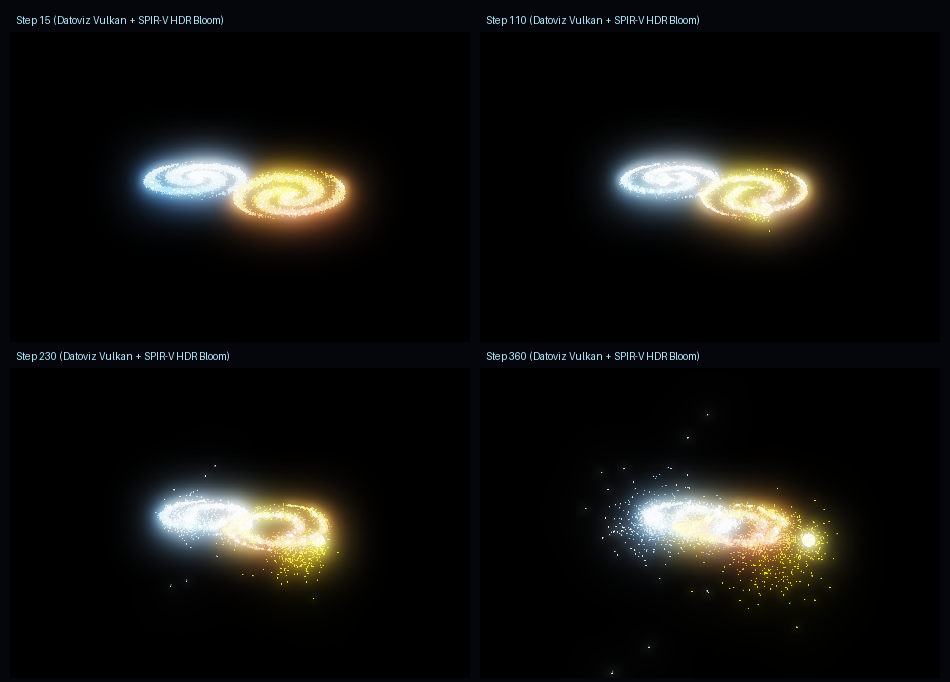

In [1]:
import sys, time
from pathlib import Path
_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
for p in (str(_root), str(_root / "examples" / "datoviz")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
from PIL import Image, ImageDraw
import vkspatial as vksp
import vkshader as vks
from datoviz_nbody_galaxies import NUM_BODIES, create_colliding_galaxies, render_datoviz_snapshot

pm0, vg0 = create_colliding_galaxies(NUM_BODIES)
sim = vksp.BarnesHut3D(pm0, vg0, G=0.025, damping=0.9999)

snaps = []
t0 = time.perf_counter()
for target in (15, 110, 230, 360):
    if target - sim.steps > 4:
        sim.step(target - sim.steps - 4)
    prev = sim.pos_mass.to_numpy()[:, :3].copy()
    sim.step(4)
    rgba = render_datoviz_snapshot(
        sim.pos_mass.to_numpy(), sim.vel_gal.to_numpy(), prev,
        width=460, height=310, yaw=0.32, pitch=0.58, dist=1.70,
    )
    bloomed = vks.hdr_bloom(rgba, intensity=0.55, exposure=1.08, threshold=0.14, hdr_lift=2.2)
    snaps.append((f"Step {sim.steps} (Datoviz Vulkan + SPIR-V HDR Bloom)", Image.fromarray(bloomed[:, :, :3], mode="RGB")))

elapsed = time.perf_counter() - t0
print(f"Simulated {sim.steps} Barnes-Hut steps + 4 Datoviz Vulkan renders + HDR Bloom in {elapsed:.2f}s")

grid = Image.new("RGB", (2 * 470 + 10, 2 * 336 + 10), (4, 6, 12))
draw = ImageDraw.Draw(grid)
for idx, (lbl, im) in enumerate(snaps):
    r, c = divmod(idx, 2)
    x0, y0 = 10 + c * 470, 10 + r * 336
    draw.text((x0 + 6, y0 + 4), lbl, fill=(180, 235, 255))
    grid.paste(im, (x0, y0 + 22))
grid

## 2. Launch Native 60+ FPS Datoviz Vulkan Window (With Dear ImGui Controls)

Click the button below to launch the native hardware-accelerated **Datoviz Vulkan desktop window** with 3D Arcball orbit and live **Dear ImGui** controls (**Running**, **Gravity G**, **Steps/Frame**, **Reset Galaxies**).

In [2]:
import os, subprocess
import ipywidgets as widgets
from IPython.display import display

script_path = _root / "examples" / "datoviz" / "datoviz_nbody_galaxies.py"
status = widgets.Label(value=f"Ready to launch: {script_path.name}")
btn = widgets.Button(description="Launch Native 60 FPS Datoviz Window", button_style="success", icon="rocket")

def _launch(_):
    env = os.environ.copy()
    env["PYTHONPATH"] = str(_root)
    subprocess.Popen([sys.executable, str(script_path)], env=env)
    status.value = "Launched Datoviz native Vulkan window (drag to orbit, scroll to zoom, use ImGui panel)!"

btn.on_click(_launch)
display(widgets.VBox([btn, status]))